# Batched CBF safety filter for 1024 robot arms

A **control barrier function (CBF) safety filter** changes a robot's nominal command as little as
possible while keeping the robot safe. At every control tick it solves a small **QP** with one linear
constraint per safety condition, and a manipulator needs many of them:
[OSCBF](https://stanfordasl.github.io/oscbf/) (Morton and Pavone, 2025) covers a Franka Panda with 21
collision spheres and checks each of them against every obstacle. Pipelines that simulate thousands of
robots usually cannot afford a numerical QP solve per robot and tick, and keep a single constraint with
a closed-form solution instead ([CBF-RL](https://arxiv.org/abs/2510.14959), Yang et al., 2025).

Here **cuPIQP** runs the full filter for **1024 Panda arms** at once: one QP per arm, with 7
variables, 105 inequality constraints and 7 box bounds, all solved in **one batched call** at every
control tick of the 250 Hz loop. [Newton](https://github.com/newton-physics/newton) provides the kinematics and the
video. Both libraries keep their data in `warp.array`s, so the QPs go from Newton's kinematics to
cuPIQP without leaving the GPU, and the whole control loop is recorded once into a **CUDA graph**.

The robot side -- the Panda model, its collision spheres, the kernels that write the QPs, logging and
rendering -- lives in [batched_robot_arm_cbf_utils.py](batched_robot_arm_cbf_utils.py). This notebook shows the
cuPIQP side. It needs [Newton](https://github.com/newton-physics/newton) with its simulation extras,
[robot_descriptions](https://github.com/robot-descriptions/robot_descriptions.py) (it downloads MuJoCo
Menagerie on first use), [mediapy](https://github.com/google/mediapy) with `ffmpeg`, and
[pyglet](https://pyglet.org).

In [1]:
%%capture
# Restart the kernel after installing or updating packages.
%pip install "newton[sim]" robot_descriptions mediapy pyglet

In [2]:
import os
import time
import numpy as np
import warp as wp
import mediapy as media
%matplotlib inline
%config InlineBackend.figure_format='retina'

wp.config.log_level = wp.LOG_WARNING  # hide Warp's start-up and kernel-loading messages

from cupiqp import DenseSolver, Status
from batched_robot_arm_cbf_utils import PandaArms, plot_runs, render_video

## The safety filter QP

Each arm is velocity-controlled: the decision variable is the vector of joint velocities
$u \in \mathbb{R}^7$. At configuration $q$, the filter solves

$$
\begin{aligned}
\min_{u}\quad & \tfrac12 \big\lVert J_{tcp}\, u - v^{\mathrm{des}} \big\rVert^2_{W}
  + \tfrac12\, w_{\mathrm{post}} \lVert u - u_{\mathrm{post}} \rVert^2 \\
\text{s.t.}\quad & n_{sj}^\top J_s\, u \;\ge\; -\alpha\, h_{sj}(q)
  \qquad \text{for every collision sphere } s \text{ and every object } j \text{ or the table}, \\
& \max\big(-u_{\max},\, \alpha_q (q_{\min} - q)\big) \;\le\; u \;\le\; \min\big(u_{\max},\, \alpha_q (q_{\max} - q)\big).
\end{aligned}
$$

- The **cost** tracks a desired gripper velocity $v^{\mathrm{des}}$ -- a sweep across the table -- and
  pulls the elbow towards a home posture. Its unconstrained minimizer is the nominal controller.
- $h_{sj}(q)$ is the distance between collision sphere $s$ of the arm and object $j$, $n_{sj}$ the unit
  normal between them and $J_s$ the Jacobian of the sphere center. The **CBF condition**
  $\dot h \ge -\alpha h$ lets a distance shrink at most exponentially, so an arm that starts safe stays
  safe. With 21 spheres, 4 objects and the table, these are the $21 \times 5 = 105$ rows of
  $G u \le h_u$.
- The **joint-limit CBFs** and the velocity limits are per-joint, so they become the box bounds.

All of $P, c, G, h_u, x_l, x_u$ change at every tick with the configuration of the arm; only the
structure stays the same. Turning the filter off ($h_u = +\infty$, velocity limits only) makes the same
QP return the nominal controller, which we use for comparison.

Every arm gets its own table with 4 objects of random size scattered around its own random sweep:

In [3]:
B = 1024
arms = PandaArms(B=B, n_objects=4, t_sim=8.0, seed=0)

print(f"{B} arms, one QP each: n = {arms.n} variables, m = {arms.m} inequalities, {arms.n} box bounds")
for name, a in arms.qp.items():
    print(f"  {name:>3}: {a.dtype.__name__} warp.array of shape {a.shape}")

1024 arms, one QP each: n = 7 variables, m = 105 inequalities, 7 box bounds
    P: float64 warp.array of shape (1024, 7, 7)
    c: float64 warp.array of shape (1024, 7)
    G: float64 warp.array of shape (1024, 105, 7)
  h_u: float64 warp.array of shape (1024, 105)
  x_l: float64 warp.array of shape (1024, 7)
  x_u: float64 warp.array of shape (1024, 7)


## Setting up cuPIQP

`arms.assemble_qps()` writes the QPs of all arms into the batched `warp.array`s above, and
`DenseSolver.setup` takes them as they are: their leading axis sets the batch size $B$, and nothing
goes through the host.

With `preconditioner_reuse_on_update = True`, `update()` keeps the Ruiz scaling computed by `setup()`
instead of computing a new one for the new data. A new scaling checks its convergence on the host,
which a CUDA graph cannot do, and the QPs of consecutive ticks are close enough to share one scaling.

In [4]:
solver = DenseSolver()
solver.settings.preconditioner_reuse_on_update = True
stream = solver.stream                      # the robot side runs on the solver's stream too

with wp.ScopedStream(stream):
    arms.assemble_qps()                     # the QPs of all arms at the home posture
solver.setup(**arms.qp)
solver.solve()

info = solver.result.info.to_host()
print(f"{info.status.count(Status.CUPIQP_SOLVED)} / {B} QPs solved, at most {info.iter.max()} iterations")

1024 / 1024 QPs solved, at most 14 iterations


## The closed loop in one CUDA graph

A control tick assembles the QPs at the current state, passes them to the solver with `update()`,
solves all 1024 of them with one `solve()`, and integrates the solutions over one tick. None of these
steps waits for the host, so we record one tick with `wp.ScopedCapture` on the solver's stream and
replay the recording with `wp.capture_launch`, 2000 times per 8 s run. The filter flag lives on the
GPU, so the same graph runs both the nominal controller (filter off) and the safety filter (filter on).

In [5]:
def control_tick():
    arms.assemble_qps()                                     # Newton kinematics -> QP data of every arm
    solver.update(**arms.qp)                                # new values, same arrays and structure
    solver.solve()                                          # all B QPs in one batched call
    arms.apply(solver.result.x, solver.result.info.status,  # integrate u over one tick, and log
               Status.CUPIQP_SOLVED.value)


with wp.ScopedStream(stream):
    control_tick()                                          # warm-up: compiles every kernel
    arms.reset()
    with wp.ScopedCapture() as capture:
        control_tick()

runs = {}
for name, enabled in (("nominal", False), ("filtered", True)):
    with wp.ScopedStream(stream):
        arms.reset()
        arms.set_filter(enabled)
        wp.synchronize_stream(stream)
        t0 = time.perf_counter()
        for _ in range(arms.n_steps):
            wp.capture_launch(capture.graph)
        wp.synchronize_stream(stream)                       # the only wait for the GPU in a run
        elapsed = time.perf_counter() - t0
    runs[name] = arms.logs()
    print(f"{name:>8}: {arms.n_steps} ticks in {elapsed:.2f} s, {elapsed / arms.n_steps * 1e3:.2f} ms per tick, "
          f"{arms.n_unsolved.numpy()[0]} of {arms.n_steps * B} QPs unsolved")

 nominal: 2000 ticks in 5.91 s, 2.96 ms per tick, 0 of 2048000 QPs unsolved
filtered: 2000 ticks in 14.50 s, 7.25 ms per tick, 0 of 2048000 QPs unsolved


A tick also contains Newton's kinematics, the QP assembly and the logging. The solve alone, on the
QPs of the last tick of the filtered run, where many arms are close to an object:

In [6]:
n_repeat = 100
wp.synchronize_stream(stream)
t0 = time.perf_counter()
for _ in range(n_repeat):
    solver.solve()
wp.synchronize_stream(stream)
solve_ms = (time.perf_counter() - t0) / n_repeat * 1e3

info = solver.result.info.to_host()
print(f"one batched solve: {solve_ms:.2f} ms for {B} QPs, {info.status.count(Status.CUPIQP_SOLVED)} / {B} solved, "
      f"iterations: median {np.median(info.iter):.0f}, max {info.iter.max()}")

one batched solve: 7.58 ms for 1024 QPs, 1024 / 1024 solved, iterations: median 13, max 21


## Results

An arm **collided** if the distance between any of its collision spheres and an object or the table
became negative at any tick. The left plot shows the smallest clearance of every arm over the run,
the right one the tracking error of the gripper over time.

 nominal:  637 / 1024 arms collided, smallest clearance  -99.1 mm; tracking error after the ramp: median 0.5 mm, 99th percentile 0.9 mm
filtered:    0 / 1024 arms collided, smallest clearance    5.0 mm; tracking error after the ramp: median 0.6 mm, 99th percentile 76.4 mm


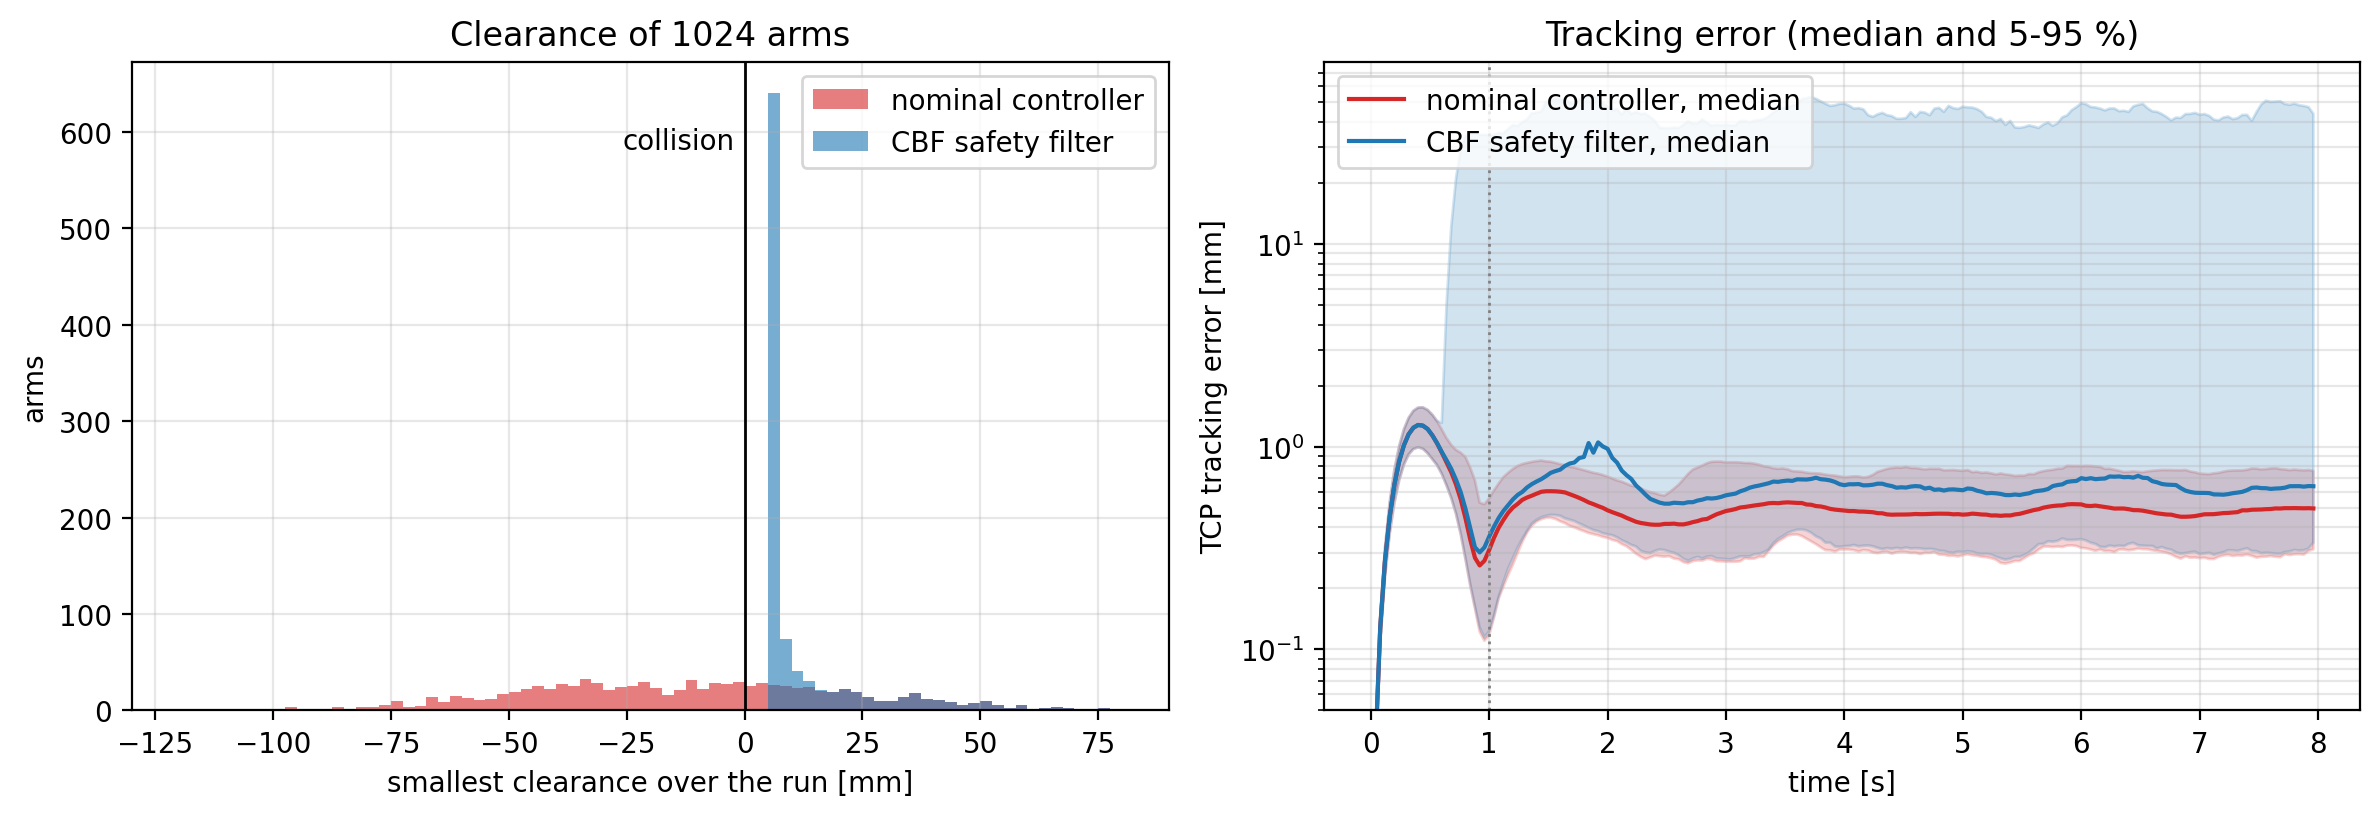

In [7]:
after_ramp = int(arms.t_ramp * arms.fps)
for name, log in runs.items():
    err = log["err"][after_ramp:] * 1e3
    print(f"{name:>8}: {(log['min_clearance'] < 0).sum():4d} / {B} arms collided, smallest clearance "
          f"{log['min_clearance'].min() * 1e3:6.1f} mm; tracking error after the ramp: "
          f"median {np.median(err):.1f} mm, 99th percentile {np.quantile(err, 0.99):.1f} mm")

plot_runs(arms, runs)

## Video

Nine arms that collided under the nominal controller, rendered with Newton's OpenGL viewer: without
the filter on the left, with it on the right. Objects turn red while the arm is inside them; the white
line is the desired path and the colored line the recent path of the gripper.

In [8]:
worlds = np.flatnonzero(runs["nominal"]["min_clearance"] < 0)[:9]
frames = render_video(arms, runs, worlds, camera=(wp.vec3(3.0, -2.7, 2.3), -28.5, 134.6))  # position, pitch, yaw [deg]
media.show_video(frames, fps=arms.fps, width=1280)

os.makedirs("videos", exist_ok=True)
media.write_video("videos/batched_cbf_panda.mp4", frames, fps=arms.fps)

This browser does not support the video tag.
